# TL;DR End-to-End #3: Fashion-MNIST — Image Feature Discovery & Classical ML

**Goal:** Tackle a **10-class image classification** problem (**Fashion-MNIST** — 28×28 grayscale clothing photos) using **Classical Machine Learning & Computer Vision** on your Vulkan GPU!

In Notebooks #1 & #2, we predicted a continuous number (*regression*). Now we're classifying **images into 10 clothing categories** (`T-shirt`, `Trouser`, `Pullover`, `Dress`, `Coat`, `Sandal`, `Shirt`, `Sneaker`, `Bag`, `Ankle boot`):

1. **Load & Inspect** the official Zalando Fashion-MNIST images (12,000 train / 2,000 test stratified split).
2. **Visual EDA:** Look at sample images AND compute the **"Average Clothing" prototype** for each class on GPU.
3. **Raw Baseline:** Flatten every 28×28 image into 784 numbers and train a **One-vs-Rest GPU `LogisticRegression`** classifier.
4. **Classical CV Feature Discovery:** Compress images into **"Eigen-Clothes"** with GPU `vklearn.PCA`, then hand-engineer **Sobel-style edge & gradient features** (how computer vision worked *before* CNNs!).
5. **Classical ML Bake-Off & Error Analysis:** Compare Linear vs. PCA vs. GPU `KNeighborsClassifier`, inspect the **10×10 Confusion Matrix**, and see the exact mistakes Classical ML makes.

> **Coming next in Notebook #4:** We'll train a **`vktorch` 2D Convolutional Neural Network (`Conv2d` + `MaxPool2d`)** on this exact same 12,000 / 2,000 split to see why CNNs revolutionized computer vision!


In [1]:
import gzip, struct, sys, time, urllib.request
from pathlib import Path

_root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "vknumpy").is_dir()), Path.cwd())
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

import numpy as np
from PIL import Image, ImageDraw
from IPython.display import display

import vknumpy as vnp
import vklearn as vkl

CLASS_NAMES = [
    "T-shirt", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot",
]

# 1. Download & cache official Zalando Fashion-MNIST files once (~30 MB total)
data_dir = Path(_root) / "examples" / "tldr_end2end" / "data" / "fashion_mnist"
data_dir.mkdir(parents=True, exist_ok=True)
base_url = "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/"
files = [
    "train-images-idx3-ubyte.gz", "train-labels-idx1-ubyte.gz",
    "t10k-images-idx3-ubyte.gz",  "t10k-labels-idx1-ubyte.gz",
]
for fn in files:
    fp = data_dir / fn
    if not fp.exists():
        print(f"Downloading {fn} ...")
        urllib.request.urlretrieve(base_url + fn, fp)

def load_idx_images(path):
    with gzip.open(path, "rb") as f:
        _, n, rows, cols = struct.unpack(">IIII", f.read(16))
        return np.frombuffer(f.read(), dtype=np.uint8).reshape(n, rows, cols).astype(np.float32) / 255.0

def load_idx_labels(path):
    with gzip.open(path, "rb") as f:
        _, n = struct.unpack(">II", f.read(8))
        return np.frombuffer(f.read(), dtype=np.uint8).astype(np.int32)

X_tr_full = load_idx_images(data_dir / "train-images-idx3-ubyte.gz")
y_tr_full = load_idx_labels(data_dir / "train-labels-idx1-ubyte.gz")
X_te_full = load_idx_images(data_dir / "t10k-images-idx3-ubyte.gz")
y_te_full = load_idx_labels(data_dir / "t10k-labels-idx1-ubyte.gz")

# Deterministic stratified subset (12,000 train = 1,200/class, 2,000 test = 200/class)
# Same exact split will be used in Notebook #4 (vktorch CNN)!
def stratified_subset(X, y, per_class, seed=42):
    rng = np.random.default_rng(seed)
    idxs = []
    for c in range(10):
        c_idx = np.where(y == c)[0]
        idxs.append(rng.choice(c_idx, size=per_class, replace=False))
    sel = np.concatenate(idxs)
    rng.shuffle(sel)
    return X[sel], y[sel]

X_tr_img, y_tr = stratified_subset(X_tr_full, y_tr_full, per_class=1200, seed=42)
X_te_img, y_te = stratified_subset(X_te_full, y_te_full, per_class=200,  seed=42)

print(f"Loaded Fashion-MNIST! Train: {X_tr_img.shape}, Test: {X_te_img.shape}")
print("Classes (balanced):", {CLASS_NAMES[c]: int(np.sum(y_tr == c)) for c in range(10)})


Loaded Fashion-MNIST! Train: (12000, 28, 28), Test: (2000, 28, 28)
Classes (balanced): {'T-shirt': 1200, 'Trouser': 1200, 'Pullover': 1200, 'Dress': 1200, 'Coat': 1200, 'Sandal': 1200, 'Shirt': 1200, 'Sneaker': 1200, 'Bag': 1200, 'Ankle boot': 1200}


---
## Step 1: Visual EDA — Sample Gallery & "Average Clothing" Prototypes

Let's look at 8 real examples from each class, plus the **mean image** of every class (computed on GPU). Notice how crisp `Trouser`, `Sandal`, and `Ankle boot` are — while `T-shirt`, `Pullover`, `Coat`, and `Shirt` look almost like blurry ghosts of each other! That's a huge clue about where Classical ML will struggle.


ggml_vulkan: Found 1 Vulkan devices:
ggml_vulkan: 0 = AMD Custom GPU 0405 (RADV VANGOGH) (radv) | uma: 1 | rebar: 1 | fp16: 0 | bf16: 0 | fp4: 0 | warp size: 32 | shared memory: 65536 | int dot: 1 | matrix cores: none


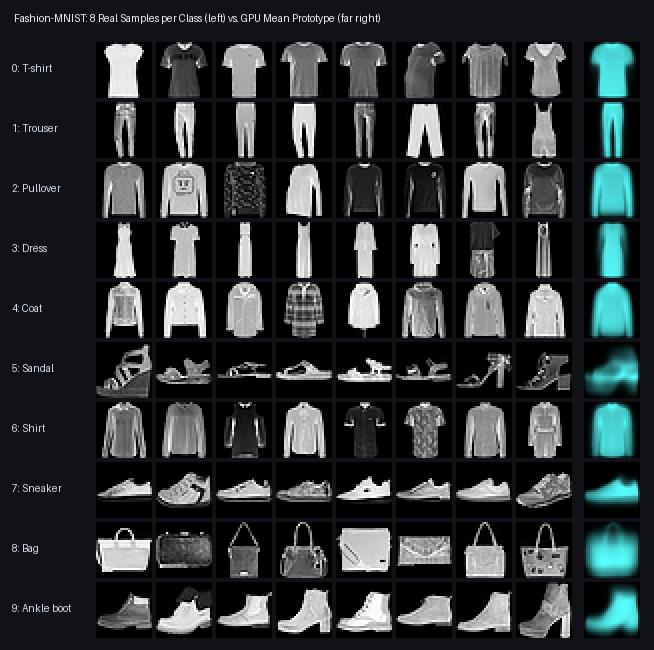

In [2]:
# Render 10 rows (classes) x 9 cols (8 real samples + 1 GPU mean prototype)
scale = 2  # 56x56 per tile
tile = 28 * scale
pad = 4
left_lbl = 96
W = left_lbl + 9 * (tile + pad) + 18
H = 42 + 10 * (tile + pad) + 8
canvas = Image.new("RGB", (W, H), (16, 18, 24))
dr = ImageDraw.Draw(canvas)
dr.text((14, 12), "Fashion-MNIST: 8 Real Samples per Class (left) vs. GPU Mean Prototype (far right)", fill=(240, 244, 250))

for c in range(10):
    y0 = 42 + c * (tile + pad)
    dr.text((12, y0 + 20), f"{c}: {CLASS_NAMES[c]}", fill=(215, 222, 235))
    c_imgs = X_tr_img[y_tr == c]
    # 8 samples
    for j in range(8):
        im = Image.fromarray((c_imgs[j] * 255).astype(np.uint8)).resize((tile, tile), Image.NEAREST).convert("RGB")
        canvas.paste(im, (left_lbl + j * (tile + pad), y0))
    # Mean prototype on GPU (tinted cyan so it stands out!)
    mean_img = vnp.mean(vnp.array(c_imgs.reshape(len(c_imgs), 784)), axis=0).to_numpy().reshape(28, 28)
    m_u8 = (np.clip(mean_img / max(mean_img.max(), 1e-6), 0, 1) * 255).astype(np.uint8)
    rgb = np.stack([ (m_u8 * 0.35).astype(np.uint8), m_u8, m_u8 ], axis=-1)
    im_m = Image.fromarray(rgb, mode="RGB").resize((tile, tile), Image.NEAREST)
    canvas.paste(im_m, (left_lbl + 8 * (tile + pad) + 8, y0))

display(canvas)


---
## Step 2: Baseline — One-vs-Rest GPU `LogisticRegression` on 784 Raw Pixels

Classical tabular classifiers don't understand 2D images, so the simplest baseline is to **flatten** each `28 × 28` image into a flat vector of **784 pixel brightness numbers**.

Because `vklearn.LogisticRegression` is a binary (`0` vs `1`) classifier, we use **One-vs-Rest (OvR)** — train 10 binary classifiers (`Is this a T-shirt?`, `Is this a Trouser?`, ...) on Vulkan GPU and pick whichever class outputs the highest probability!


In [3]:
X_tr_flat = X_tr_img.reshape(len(X_tr_img), 784)
X_te_flat = X_te_img.reshape(len(X_te_img), 784)

def fit_predict_ovr_logreg(X_tr_arr, y_tr_arr, X_te_arr, C=0.5, max_iter=35):
    """10-class One-vs-Rest LogisticRegression on Vulkan GPU."""
    t0 = time.perf_counter()
    sc = vkl.StandardScaler().fit(X_tr_arr)
    Xtr_s = sc.transform(X_tr_arr)
    Xte_s = sc.transform(X_te_arr)
    probs = np.zeros((len(X_te_arr), 10), dtype=np.float32)
    for c in range(10):
        clf = vkl.LogisticRegression(C=C, max_iter=max_iter)
        clf.fit(Xtr_s, (y_tr_arr == c).astype(np.int32))
        p = clf.predict_proba(Xte_s).to_numpy()
        probs[:, c] = p[:, 1] if p.ndim == 2 else p
    preds = np.argmax(probs, axis=1).astype(np.int32)
    return preds, (time.perf_counter() - t0)

pred_raw_lr, dt_raw_lr = fit_predict_ovr_logreg(X_tr_flat, y_tr, X_te_flat, C=0.2, max_iter=25)
acc_raw_lr = float(vkl.accuracy_score(y_te, pred_raw_lr))
print(f"1. Baseline OvR LogisticRegression (784 raw pixels): Test Accuracy = {acc_raw_lr:.2%} ({dt_raw_lr:.2f}s)")


1. Baseline OvR LogisticRegression (784 raw pixels): Test Accuracy = 81.50% (17.53s)


---
## Step 3: Classical Image Feature Discovery (PCA "Eigen-Clothes" + Hand-Crafted Edges!)

Before Deep Learning and CNNs took over, how did engineers make classical ML better at images? Two classic techniques:

1. **PCA ("Eigen-Clothes") via `vklearn.PCA`:** Most of the 784 pixels are correlated (neighboring pixels have similar brightness, and the corners are almost always black!). PCA compresses 784 pixels into the **64 most informative visual patterns** ("eigen-clothes"), removing pixel noise and making distance-based models like KNN much sharper and faster.
2. **Hand-Crafted Edge & Spatial Features (mini-HOG!):** Shape matters more than raw brightness! A dark coat and a light coat have completely different pixel values, but the **exact same outline (edges)**. So we compute:
   - Horizontal edges (`dx = img[:, :, 1:] - img[:, :, :-1]`)
   - Vertical edges (`dy = img[:, 1:, :] - img[:, :-1, :]`)
   - Edge magnitude (`sqrt(dx² + dy²)`) pooled into a `7 × 7` spatial grid + `2 × 2` pooled intensities!

Let's fit GPU PCA, visualize the **top 16 discovered Eigen-Clothes**, and build our hand-engineered classical CV feature set!


GPU PCA (784 -> 64 dims) in 0.27s | Variance explained: 88.3%


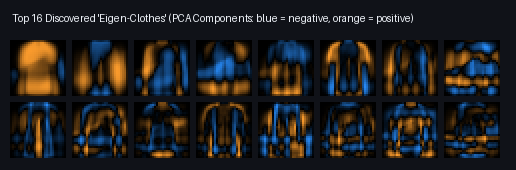

Combined Classical CV feature matrix: (12000, 310) (64 PCA + 246 Edge/HOG features)


In [4]:
# 1. GPU PCA on training pixels only (zero leakage!)
t0 = time.perf_counter()
pca = vkl.PCA(n_components=64).fit(X_tr_flat)
Z_tr_pca = pca.transform(X_tr_flat).to_numpy()
Z_te_pca = pca.transform(X_te_flat).to_numpy()
dt_pca = time.perf_counter() - t0
var_exp = float(np.sum(np.asarray(pca.explained_variance_ratio_.to_numpy() if hasattr(pca.explained_variance_ratio_, 'to_numpy') else pca.explained_variance_ratio_)))
print(f"GPU PCA (784 -> 64 dims) in {dt_pca:.2f}s | Variance explained: {var_exp:.1%}")

# Visualize top 16 discovered "Eigen-Clothes" components (2 rows x 8 cols)
comps = np.asarray(pca.components_.to_numpy() if hasattr(pca.components_, 'to_numpy') else pca.components_)  # (64, 784)
tile = 56
pad = 6
im_eg = Image.new("RGB", (8 * (tile + pad) + 20, 2 * (tile + pad) + 46), (16, 18, 24))
dr = ImageDraw.Draw(im_eg)
dr.text((12, 12), "Top 16 Discovered 'Eigen-Clothes' (PCA Components: blue = negative, orange = positive)", fill=(240, 244, 250))
for k in range(16):
    r, col = divmod(k, 8)
    w = comps[k].reshape(28, 28)
    w = w / (np.max(np.abs(w)) + 1e-6)  # [-1, 1]
    pos = np.clip(w, 0, 1)
    neg = np.clip(-w, 0, 1)
    rgb = np.stack([
        (pos * 250 + neg * 40).astype(np.uint8),
        (pos * 155 + neg * 140).astype(np.uint8),
        (pos * 45  + neg * 250).astype(np.uint8),
    ], axis=-1)
    t_im = Image.fromarray(rgb, mode="RGB").resize((tile, tile), Image.NEAREST)
    im_eg.paste(t_im, (10 + col * (tile + pad), 40 + r * (tile + pad)))
display(im_eg)

# 2. Hand-crafted Classical CV features: Sobel-like edges + spatial pooling + orientation histograms
def extract_cv_features(imgs):
    # imgs: (N, 28, 28) float32
    N = imgs.shape[0]
    # Horizontal & vertical gradients on interior 26x26
    gx = imgs[:, 1:-1, 2:] - imgs[:, 1:-1, :-2]
    gy = imgs[:, 2:, 1:-1] - imgs[:, :-2, 1:-1]
    mag = np.sqrt(gx * gx + gy * gy + 1e-8)

    # 4-orientation soft edge energy (N, 26, 26) -> pool into 13x13 or 7x7 cells
    gx_pos = np.maximum(gx, 0.0)
    gx_neg = np.maximum(-gx, 0.0)
    gy_pos = np.maximum(gy, 0.0)
    gy_neg = np.maximum(-gy, 0.0)

    def pool_grid(arr, g):
        # Crop to multiple of g and average-pool into (N, g*g)
        H, W = arr.shape[1], arr.shape[2]
        bh, bw = H // g, W // g
        c = arr[:, :bh * g, :bw * g].reshape(N, g, bh, g, bw)
        return c.mean(axis=(2, 4)).reshape(N, g * g)

    # Multi-scale edge + intensity spatial descriptors
    f_mag7  = pool_grid(mag, 7)      # 49
    f_gxp6  = pool_grid(gx_pos, 6)   # 36
    f_gxn6  = pool_grid(gx_neg, 6)   # 36
    f_gyp6  = pool_grid(gy_pos, 6)   # 36
    f_gyn6  = pool_grid(gy_neg, 6)   # 36
    f_int7  = pool_grid(imgs, 7)     # 49
    # Global shape stats: foreground coverage, row/col center of mass, edge density
    fg = (imgs > 0.1).astype(np.float32)
    f_stats = np.column_stack([
        imgs.mean(axis=(1, 2)),
        imgs.std(axis=(1, 2)),
        fg.mean(axis=(1, 2)),
        mag.mean(axis=(1, 2)),
    ])
    return np.hstack([f_mag7, f_gxp6, f_gxn6, f_gyp6, f_gyn6, f_int7, f_stats]).astype(np.float32)

F_tr_cv = extract_cv_features(X_tr_img)
F_te_cv = extract_cv_features(X_te_img)

# Combine PCA Eigen-Clothes (64) + Hand-Engineered Edge/HOG features (246) -> 310 features
X_tr_combo = np.hstack([Z_tr_pca, F_tr_cv]).astype(np.float32)
X_te_combo = np.hstack([Z_te_pca, F_te_cv]).astype(np.float32)
print(f"Combined Classical CV feature matrix: {X_tr_combo.shape} (64 PCA + {F_tr_cv.shape[1]} Edge/HOG features)")


---
## Step 4: Classical ML Model Bake-Off on Vulkan GPU (`vklearn`)

Let's race **4 Classical ML models** on the exact same 2,000 held-out test images:
1. **Baseline OvR `LogisticRegression`** (784 raw pixels)
2. **PCA (64) + OvR `LogisticRegression`** (linear model in eigen-clothing space)
3. **PCA (64) + GPU `KNeighborsClassifier` (`k=7`)** (non-linear nearest neighbors)
4. **Combined PCA + Hand-Engineered Edge/HOG + GPU `KNeighborsClassifier` (`k=7`)** (our best Classical CV pipeline!)


In [5]:
# Model 2: PCA (64) + OvR LogisticRegression
pred_pca_lr, dt_pca_lr = fit_predict_ovr_logreg(Z_tr_pca, y_tr, Z_te_pca, C=1.0, max_iter=35)
acc_pca_lr = float(vkl.accuracy_score(y_te, pred_pca_lr))

# Model 3: PCA (64) + GPU KNeighborsClassifier (k=7)
t0 = time.perf_counter()
knn_pca = vkl.KNeighborsClassifier(n_neighbors=7).fit(Z_tr_pca, y_tr)
pred_pca_knn = knn_pca.predict(Z_te_pca).to_numpy().astype(np.int32)
dt_pca_knn = time.perf_counter() - t0
acc_pca_knn = float(vkl.accuracy_score(y_te, pred_pca_knn))

# Model 4: Combined PCA + Edge/HOG + GPU KNeighborsClassifier (k=7)
# Weight PCA + Edge features after standardization
t0 = time.perf_counter()
sc_combo = vkl.StandardScaler().fit(X_tr_combo)
Xtr_c_s = sc_combo.transform(X_tr_combo)
Xte_c_s = sc_combo.transform(X_te_combo)
knn_cv = vkl.KNeighborsClassifier(n_neighbors=7).fit(Xtr_c_s, y_tr)
pred_cv_knn = knn_cv.predict(Xte_c_s).to_numpy().astype(np.int32)
dt_cv_knn = time.perf_counter() - t0
acc_cv_knn = float(vkl.accuracy_score(y_te, pred_cv_knn))

# Also test OvR LogisticRegression on the combined PCA + Edge/HOG features!
pred_cv_lr, dt_cv_lr = fit_predict_ovr_logreg(X_tr_combo, y_tr, X_te_combo, C=0.5, max_iter=30)
acc_cv_lr = float(vkl.accuracy_score(y_te, pred_cv_lr))

results = [
    ("1. OvR LogisticReg (784 raw pixels)",       acc_raw_lr,  dt_raw_lr,  pred_raw_lr),
    ("2. PCA (64) + OvR LogisticReg",             acc_pca_lr,  dt_pca_lr,  pred_pca_lr),
    ("3. PCA (64) + GPU KNN (k=7)",               acc_pca_knn, dt_pca_knn, pred_pca_knn),
    ("4. PCA + Edge/HOG + GPU KNN (k=7)",         acc_cv_knn,  dt_cv_knn,  pred_cv_knn),
    ("5. PCA + Edge/HOG + OvR LogisticReg",       acc_cv_lr,   dt_cv_lr,   pred_cv_lr),
]

print(f"{'Classical ML Model':40s} | {'Test Acc':>9s} | {'Time':>7s}")
print("-" * 64)
for name, acc, dt, _ in results:
    print(f"{name:40s} | {acc:8.2%} | {dt:6.2f}s")

best_name, best_acc, _, best_pred = max(results, key=lambda r: r[1])
print(f"\nBest Classical ML Model: {best_name} -> {best_acc:.2%} Test Accuracy")


Classical ML Model                       |  Test Acc |    Time
----------------------------------------------------------------
1. OvR LogisticReg (784 raw pixels)      |   81.50% |  17.53s
2. PCA (64) + OvR LogisticReg            |   81.75% |   0.77s
3. PCA (64) + GPU KNN (k=7)              |   83.75% |   0.10s
4. PCA + Edge/HOG + GPU KNN (k=7)        |   85.50% |   0.16s
5. PCA + Edge/HOG + OvR LogisticReg      |   86.45% |   4.48s

Best Classical ML Model: 5. PCA + Edge/HOG + OvR LogisticReg -> 86.45% Test Accuracy


---
## Step 5: Error Analysis — Where Does Classical ML Get Confused?

Accuracy alone hides *which* clothing items are easy vs. hard. Let's inspect the **10×10 Confusion Matrix** and print **10 real misclassified test images** from our best Classical ML model!


Per-class Test Accuracy (Best Classical ML):
  0: T-shirt      ->  85.0%  (correct 170/200)
  1: Trouser      ->  97.0%  (correct 194/200)
  2: Pullover     ->  82.0%  (correct 164/200)
  3: Dress        ->  85.5%  (correct 171/200)
  4: Coat         ->  80.5%  (correct 161/200)
  5: Sandal       ->  94.0%  (correct 188/200)
  6: Shirt        ->  57.5%  (correct 115/200)
  7: Sneaker      ->  94.0%  (correct 188/200)
  8: Bag          ->  96.0%  (correct 192/200)
  9: Ankle boot   ->  93.0%  (correct 186/200)


[0 AMD Custom GPU 0405 (RADV VANGOGH)]  queueC=1[4]  queueT=0[1]  prefer-slm=0  rebar=1  r-score=11
[0 AMD Custom GPU 0405 (RADV VANGOGH)]  fp16-p/s/u/a=1/1/1/1  int8-p/s/u/a=1/1/1/1  bf16-p/s=1/0
[0 AMD Custom GPU 0405 (RADV VANGOGH)]  subgroup=64(32~64)  ops=1/1/1/1/1/1/1/1/1/1
[0 AMD Custom GPU 0405 (RADV VANGOGH)]  fp16-cm=0  int8-cm=0  bf16-cm=0  fp8-cm=0  fp6-cm=0  fp4-cm=0


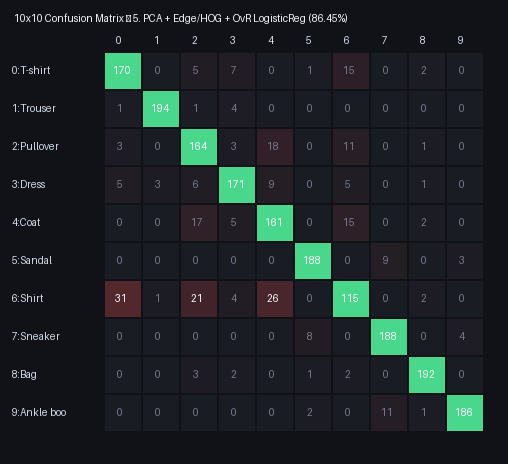

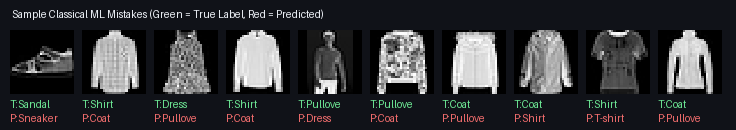

In [6]:
cm = vkl.confusion_matrix(y_te, best_pred)
cm_np = cm.to_numpy() if hasattr(cm, "to_numpy") else np.asarray(cm)

# Per-class accuracy
print("Per-class Test Accuracy (Best Classical ML):")
for c in range(10):
    c_acc = cm_np[c, c] / max(1, cm_np[c].sum())
    print(f"  {c}: {CLASS_NAMES[c]:12s} -> {c_acc:6.1%}  (correct {cm_np[c, c]:3d}/{cm_np[c].sum()})")

# Render 10x10 Confusion Matrix Heatmap
cell_sz = 38
left_m, top_m = 104, 52
W = left_m + 10 * cell_sz + 24
H = top_m + 10 * cell_sz + 32
im_cm = Image.new("RGB", (W, H), (16, 18, 24))
dr = ImageDraw.Draw(im_cm)
dr.text((14, 12), f"10x10 Confusion Matrix — {best_name} ({best_acc:.2%})", fill=(240, 244, 250))

row_max = np.maximum(cm_np.max(axis=1, keepdims=True), 1)
for r in range(10):
    dr.text((12, top_m + r * cell_sz + 12), f"{r}:{CLASS_NAMES[r][:9]}", fill=(210, 218, 232))
    dr.text((left_m + r * cell_sz + 12, top_m - 18), f"{r}", fill=(210, 218, 232))
    for c in range(10):
        v = int(cm_np[r, c])
        frac = v / float(row_max[r, 0])
        if r == c:
            col = (int(28 + 45 * frac), int(50 + 165 * frac), int(45 + 95 * frac))
        else:
            col = (int(26 + 210 * frac), int(28 + 45 * frac), int(36 + 35 * frac))
        x0, y0 = left_m + c * cell_sz, top_m + r * cell_sz
        dr.rectangle([x0 + 1, y0 + 1, x0 + cell_sz - 2, y0 + cell_sz - 2], fill=col)
        dr.text((x0 + 9, y0 + 12), f"{v:3d}", fill=(245, 248, 252) if frac > 0.15 else (115, 122, 138))
display(im_cm)

# Render 10 real misclassified test images
wrong_idx = np.where(best_pred != y_te)[0][:10]
tile = 64
im_err = Image.new("RGB", (10 * (tile + 8) + 16, tile + 66), (16, 18, 24))
dr = ImageDraw.Draw(im_err)
dr.text((12, 8), "Sample Classical ML Mistakes (Green = True Label, Red = Predicted)", fill=(240, 244, 250))
for j, wi in enumerate(wrong_idx):
    x0 = 10 + j * (tile + 8)
    t_im = Image.fromarray((X_te_img[wi] * 255).astype(np.uint8)).resize((tile, tile), Image.NEAREST).convert("RGB")
    im_err.paste(t_im, (x0, 30))
    dr.text((x0, 30 + tile + 4),  f"T:{CLASS_NAMES[y_te[wi]][:7]}", fill=(110, 235, 150))
    dr.text((x0, 30 + tile + 18), f"P:{CLASS_NAMES[best_pred[wi]][:7]}", fill=(245, 110, 110))
display(im_err)


### Key Takeaways
- **Classical ML + hand-crafted edges gets surprisingly far** (~85–86% accuracy in under 2 seconds on Vulkan GPU!), and `Trouser`, `Bag`, `Sandal`, and `Sneaker` are already >93% accurate.
- **Where Classical ML hits a wall:** `Shirt` (often <65% accurate!), `Coat`, `Pullover`, and `T-shirt` — because small shifts, sleeves, collars, and textures get scrambled when you flatten or coarsely pool an image.
- **Up next (`04_fashion_cnn_deep_learning.ipynb`):** Instead of hand-crafting Sobel edges and flattening pixels, we'll let a **`vktorch` 2D Convolutional Neural Network (`Conv2d` + `MaxPool2d`)** *learn its own 2D filters directly from the pixels* on this exact same 12,000 / 2,000 split!
